In [28]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Annotated
from dotenv import load_dotenv
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

In [29]:
load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [30]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [31]:
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).text

    return {'joke': response}

In [32]:
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).text

    return {'explanation': response}

In [33]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

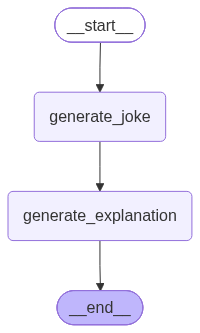

In [34]:
workflow

In [35]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({"topic": "programmig"}, config=config1)

{'topic': 'programmig',
 'joke': 'Why do programmers prefer dark mode?\n\nBecause light attracts bugs.',
 'explanation': 'Here is the explanation for the joke:\n\nThe joke relies on a **double meaning** (a pun) of the word **"bug."**\n\n1. **In programming:** A "bug" is a mistake, flaw, or error in the code that causes a program to malfunction or crash. Programmers spend a lot of time finding and fixing these bugs (known as "debugging").\n2. **In nature:** A "bug" is an insect, and many nocturnal insects are naturally attracted to bright sources of light. \n\n**The Punchline:** \nSince computer screens act as a light source, using **light mode** (a bright white screen) would theoretically attract insects ("bugs") in real life. However, programmers use the double meaning to joke that a bright screen would also attract programming errors ("bugs") into their code. Therefore, they prefer **dark mode** to keep the bugs away!'}

In [36]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'programmig', 'joke': 'Why do programmers prefer dark mode?\n\nBecause light attracts bugs.', 'explanation': 'Here is the explanation for the joke:\n\nThe joke relies on a **double meaning** (a pun) of the word **"bug."**\n\n1. **In programming:** A "bug" is a mistake, flaw, or error in the code that causes a program to malfunction or crash. Programmers spend a lot of time finding and fixing these bugs (known as "debugging").\n2. **In nature:** A "bug" is an insect, and many nocturnal insects are naturally attracted to bright sources of light. \n\n**The Punchline:** \nSince computer screens act as a light source, using **light mode** (a bright white screen) would theoretically attract insects ("bugs") in real life. However, programmers use the double meaning to joke that a bright screen would also attract programming errors ("bugs") into their code. Therefore, they prefer **dark mode** to keep the bugs away!'}, next=(), config={'configurable': {'thread_id

In [37]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'programmig', 'joke': 'Why do programmers prefer dark mode?\n\nBecause light attracts bugs.', 'explanation': 'Here is the explanation for the joke:\n\nThe joke relies on a **double meaning** (a pun) of the word **"bug."**\n\n1. **In programming:** A "bug" is a mistake, flaw, or error in the code that causes a program to malfunction or crash. Programmers spend a lot of time finding and fixing these bugs (known as "debugging").\n2. **In nature:** A "bug" is an insect, and many nocturnal insects are naturally attracted to bright sources of light. \n\n**The Punchline:** \nSince computer screens act as a light source, using **light mode** (a bright white screen) would theoretically attract insects ("bugs") in real life. However, programmers use the double meaning to joke that a bright screen would also attract programming errors ("bugs") into their code. Therefore, they prefer **dark mode** to keep the bugs away!'}, next=(), config={'configurable': {'thread_i

In [38]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({"topic": "pasta"}, config=config2)

{'topic': 'pasta',
 'joke': "What is a carb’s favorite type of music?\n\n**Ravi-oli, ravi-oli, give me the formu-oli!** \n\n*(Okay, bad music choice. Let's try again...)*\n\nWhy did the spaghetti go to the casino?\n\nBecause it wanted to **penne-trate** the high-roller life, but it ended up getting **strained**!\n\n*(Wait, no, keep it clean:)*\n\nWhat do you call a fake noodle?\n\nAn **impasta**!",
 'explanation': 'Here is an explanation of the humor, layer by layer, as the "comedian" struggles through their set:\n\n### 1. The Setup (The Premise)\n> **What is a carb’s favorite type of music?**\n\nThis is a standard setup for a riddle or a joke, promising a pun about music genres (like "Rock," "Pop," or "Jazz") combined with carbohydrates (bread, pasta, rice, etc.). \n\n### 2. The First False Start\n> **Ravi-oli, ravi-oli, give me the formu-oli!** *(Okay, bad music choice...)*\n\nInstead of a music genre, the punchline panics and references a famous meme. This is a quote from the cartoo

In [39]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pasta', 'joke': "What is a carb’s favorite type of music?\n\n**Ravi-oli, ravi-oli, give me the formu-oli!** \n\n*(Okay, bad music choice. Let's try again...)*\n\nWhy did the spaghetti go to the casino?\n\nBecause it wanted to **penne-trate** the high-roller life, but it ended up getting **strained**!\n\n*(Wait, no, keep it clean:)*\n\nWhat do you call a fake noodle?\n\nAn **impasta**!", 'explanation': 'Here is an explanation of the humor, layer by layer, as the "comedian" struggles through their set:\n\n### 1. The Setup (The Premise)\n> **What is a carb’s favorite type of music?**\n\nThis is a standard setup for a riddle or a joke, promising a pun about music genres (like "Rock," "Pop," or "Jazz") combined with carbohydrates (bread, pasta, rice, etc.). \n\n### 2. The First False Start\n> **Ravi-oli, ravi-oli, give me the formu-oli!** *(Okay, bad music choice...)*\n\nInstead of a music genre, the punchline panics and references a famous meme. This is a qu

In [40]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': "What is a carb’s favorite type of music?\n\n**Ravi-oli, ravi-oli, give me the formu-oli!** \n\n*(Okay, bad music choice. Let's try again...)*\n\nWhy did the spaghetti go to the casino?\n\nBecause it wanted to **penne-trate** the high-roller life, but it ended up getting **strained**!\n\n*(Wait, no, keep it clean:)*\n\nWhat do you call a fake noodle?\n\nAn **impasta**!", 'explanation': 'Here is an explanation of the humor, layer by layer, as the "comedian" struggles through their set:\n\n### 1. The Setup (The Premise)\n> **What is a carb’s favorite type of music?**\n\nThis is a standard setup for a riddle or a joke, promising a pun about music genres (like "Rock," "Pop," or "Jazz") combined with carbohydrates (bread, pasta, rice, etc.). \n\n### 2. The First False Start\n> **Ravi-oli, ravi-oli, give me the formu-oli!** *(Okay, bad music choice...)*\n\nInstead of a music genre, the punchline panics and references a famous meme. This is a q

Time Travel

In [43]:
workflow.get_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f1e0e0c-21c6-6602-8000-fab420ef984f"}})

StateSnapshot(values={'topic': 'programmig'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1e0e0c-21c6-6602-8000-fab420ef984f'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-15T10:38:55.913306+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e0e0c-21c4-60fc-bfff-1a9e70981fcc'}}, tasks=(PregelTask(id='65ffcefb-671d-4cd7-2399-39ed87e7fad0', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why do programmers prefer dark mode?\n\nBecause light attracts bugs.'}),), interrupts=())

In [44]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f1e0e0c-21c6-6602-8000-fab420ef984f"}})

{'topic': 'programmig',
 'joke': "There are 10 types of people in the world: \n\nThose who understand binary, and those who don't.",
 'explanation': 'Here is an explanation of the joke, broken down step-by-step:\n\n**1. The Setup: "10 types of people..."**\nThe joke starts by using the number **10** (one-zero). In our everyday numbering system (base-10, or decimal), "10" means the number **two**. \n\n**2. The Punchline: Binary**\nThe joke relies on **binary code**, which is the foundational language of computers. Binary only uses two digits: **0 and 1**. \n\nIn binary, the numbers are counted like this:\n*   `0` = zero\n*   `1` = one\n*   **`10` = two** (In binary, "10" means one group of two and zero ones).\n*   `11` = three\n*   `100` = four\n\n**3. The Irony**\nWhen you read the joke out loud, you naturally say the digit "ten" ("There are *ten* types of people..."). However, because the joke is about binary, that "10" is actually meant to be read as the number **two**. \n\nSo, the j

In [45]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'programmig', 'joke': "There are 10 types of people in the world: \n\nThose who understand binary, and those who don't.", 'explanation': 'Here is an explanation of the joke, broken down step-by-step:\n\n**1. The Setup: "10 types of people..."**\nThe joke starts by using the number **10** (one-zero). In our everyday numbering system (base-10, or decimal), "10" means the number **two**. \n\n**2. The Punchline: Binary**\nThe joke relies on **binary code**, which is the foundational language of computers. Binary only uses two digits: **0 and 1**. \n\nIn binary, the numbers are counted like this:\n*   `0` = zero\n*   `1` = one\n*   **`10` = two** (In binary, "10" means one group of two and zero ones).\n*   `11` = three\n*   `100` = four\n\n**3. The Irony**\nWhen you read the joke out loud, you naturally say the digit "ten" ("There are *ten* types of people..."). However, because the joke is about binary, that "10" is actually meant to be read as the number **

Updating State

In [46]:
workflow.update_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f1e0e0c-21c6-6602-8000-fab420ef984f", "checkpoint_ns": ""}}, {"topic": "samosa"})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e0e11-6345-6da8-8001-d85547d68d3c'}}

In [47]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e0e11-6345-6da8-8001-d85547d68d3c'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-15T10:41:16.998989+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1e0e0c-21c6-6602-8000-fab420ef984f'}}, tasks=(PregelTask(id='9d90efe4-edeb-bb5f-e40e-aa3e14038e94', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'programmig', 'joke': "There are 10 types of people in the world: \n\nThose who understand binary, and those who don't.", 'explanation': 'Here is an explanation of the joke, broken down step-by-step:\n\n**1. The Setup: "10 types of people..."**\nThe joke starts by using the number **10** (one-zero). In our everyday numbering system (base-10, or d

In [48]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f1e0e11-6345-6da8-8001-d85547d68d3c"}})

{'topic': 'samosa',
 'joke': 'Why did the samosa go to the therapist?\n\nBecause it had too many mixed feelings bottled up inside, and it felt like everyone was just trying to eat its outer shell without appreciating its spicy personality!',
 'explanation': 'Here is an explanation of the joke, broken down by its layers:\n\n1. **The Setup ("Why did the samosa go to the therapist?"):** \n   A samosa is a popular South Asian triangular pastry. By imagining it going to therapy, the joke gives the food human emotions and mental health struggles, which is a classic setup for absurd humor.\n\n2. **The Pun ("mixed feelings bottled up inside"):** \n   * **Literal meaning:** A traditional samosa is stuffed with a "mixed" filling made of potatoes, peas, and various spices. Because it is wrapped tightly in dough, these ingredients are literally "bottled up inside" the pastry shell.\n   * **Emotional meaning:** In human terms, having "mixed feelings" and keeping them "bottled up" means you are conf

In [49]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa go to the therapist?\n\nBecause it had too many mixed feelings bottled up inside, and it felt like everyone was just trying to eat its outer shell without appreciating its spicy personality!', 'explanation': 'Here is an explanation of the joke, broken down by its layers:\n\n1. **The Setup ("Why did the samosa go to the therapist?"):** \n   A samosa is a popular South Asian triangular pastry. By imagining it going to therapy, the joke gives the food human emotions and mental health struggles, which is a classic setup for absurd humor.\n\n2. **The Pun ("mixed feelings bottled up inside"):** \n   * **Literal meaning:** A traditional samosa is stuffed with a "mixed" filling made of potatoes, peas, and various spices. Because it is wrapped tightly in dough, these ingredients are literally "bottled up inside" the pastry shell.\n   * **Emotional meaning:** In human terms, having "mixed feelings" and keeping them "bottled up

Fault Tolerance

In [50]:
import time

In [51]:
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str

In [52]:
def step_1(state: CrashState) -> CrashState:
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}

def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)")
    time.sleep(10000)  # Simulate long-running hang
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}

In [53]:
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

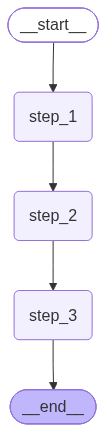

In [54]:
graph

In [ ]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")

▶️ Running graph: Please manually interrupt during Step 2...
✅ Step 1 executed
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)


In [ ]:
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)


🔁 Re-running the graph to demonstrate fault tolerance...


NameError: name 'graph' is not defined